# Task 3 — Extrinsic evaluation

An extrinsic evaluation measures a language model by how much it helps a downstream task. Two tasks:

1. **News-category classification** (main result). One language model per category; a document goes
   to the category whose model assigns it the highest probability.
2. **Next-word prediction and keystroke savings** (secondary). The GPAC models suggest the next word
   while held-out GPAC sentences are typed; this is the mechanism behind the Task 4 application.

## 3.1 News classification with one language model per class

**Data:** the Amharic News Text Classification dataset (Azime & Mohammed, 2021): 51,483 articles from
press.et in 6 categories. The classes are imbalanced: national news is 40 % of the articles, so a
classifier that always answers "national news" already reaches 40 % accuracy. Macro-F1 (the
unweighted mean of per-class F1) is therefore reported next to accuracy. Download
`data/Amharic News Dataset.zip` from
https://github.com/IsraelAbebe/An-Amharic-News-Text-classification-Dataset and unzip it into
`data/news/`.

**Method.** For each category c, a Kneser-Ney n-gram model P_class(· | c) is trained on that
category's training articles. A test document d gets the label

ĉ = argmax_c [ log P(c) + Σ_j log P_c(w_j | h_j) ]

where P(c) is the category's share of training documents and the sum runs over the document's
tokens. The per-class models see only a few million tokens each, so we also interpolate each one
with the GPAC model of the same order, P_c(w | h) = λ · P_class(w | h) + (1 − λ) · P_GPAC(w | h).
λ (the weight of the class model) is chosen by macro-F1 on a dev split; λ = 1 means class models
only. Articles are split 80 / 10 / 10 into train / dev / test, stratified by category.

In [1]:
# --- Setup ---------------------------------------------------------------------------
# On Colab / Kaggle, first get this repository and the corpus:
#   !git clone <your-repo-url> nlp-assignment-1
#   %cd nlp-assignment-1
#   !pip install -q wordcloud gdown
#   !gdown 1jEOAORylTBAiNKes_JerD6gFF7cnLFyr -O data/   # GPAC, from the assignment's Drive link
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
CORPUS = os.path.join(DATA, "GPAC.txt")     # a .txt file, a directory of .txt files, or a .zip
MODEL_DIR = os.path.join(DATA, "gpac")      # preprocessed splits, vocabulary and counts go here
FIGURES = os.path.join(ROOT, "figures"); os.makedirs(FIGURES, exist_ok=True)
MAX_CHARS = None                            # e.g. 50_000_000 to use only part of the corpus

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)

In [2]:
NEWS_CSV = os.path.join(DATA, "news", "Amharic News Dataset.csv")
news = pd.read_csv(NEWS_CSV, usecols=["article", "category"]).dropna()
print(news.shape); display(news.category.value_counts())

(51482, 2)


category
ሀገር አቀፍ ዜና    20674
ስፖርት          10411
ፖለቲካ           9325
ዓለም አቀፍ ዜና     6543
ቢዝነስ           3894
መዝናኛ            635
Name: count, dtype: int64

In [3]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from ngram import pipeline
from ngram.evaluate import encode_documents

vocab, counts, ids, stats = pipeline.load(MODEL_DIR)
# Each article becomes an int32 id array under the GPAC vocabulary (words outside it -> <unk>).
news["ids"] = encode_documents(vocab, news.article)
news = news[news.ids.map(len) > 2].drop(columns="article")
tr, rest = train_test_split(news, test_size=0.2, stratify=news.category, random_state=13)
dv, te = train_test_split(rest, test_size=0.5, stratify=rest.category, random_state=13)
print(f"train {len(tr):,} / dev {len(dv):,} / test {len(te):,} articles")
majority = tr.category.value_counts().idxmax()
print(f"majority-class baseline: accuracy {np.mean(te.category == majority):.4f}, "
      f"macro F1 {f1_score(te.category, [majority] * len(te), average='macro'):.4f}")

train 40,794 / dev 5,099 / test 5,100 articles
majority-class baseline: accuracy 0.4029, macro F1 0.0957


In [4]:
from ngram.models import KneserNeyModel
from ngram.evaluate import ClassLMClassifier

LAMBDAS = [1.0, 0.9, 0.7, 0.5, 0.3, 0.1]
results, best = [], {}
for n in range(1, 5):
    clf = ClassLMClassifier(len(vocab), n, background=KneserNeyModel(counts, n))
    cache = clf.fit_score(list(tr.ids), list(tr.category), {"dev": list(dv.ids), "test": list(te.ids)})
    dev_f1 = {lam: f1_score(dv.category, clf.predict(cache["dev"], lam), average="macro") for lam in LAMBDAS}
    lam_best = max(dev_f1, key=dev_f1.get)
    for name, lam in (("class LM only", 1.0), (f"+ GPAC (λ={lam_best})", lam_best)):
        pred = clf.predict(cache["test"], lam)
        results.append({"n": n, "model": name, "accuracy": accuracy_score(te.category, pred),
                        "macro F1": f1_score(te.category, pred, average="macro")})
        best[(n, name.split(" (")[0])] = pred
    del clf, cache
    counts._stats = None   # drop the GPAC Kneser-Ney aggregates of this order before the next
res = pd.DataFrame(results)
display(res.round(4))

,n,model,accuracy,macro F1
0,1,class LM only,0.7733,0.7374
1,1,+ GPAC (λ=1.0),0.7733,0.7374
2,2,class LM only,0.8275,0.7763
3,2,+ GPAC (λ=0.7),0.8412,0.8049
4,3,class LM only,0.8282,0.7764
5,3,+ GPAC (λ=0.3),0.8375,0.8043
6,4,class LM only,0.8312,0.7793
7,4,+ GPAC (λ=0.3),0.8345,0.8004


              precision    recall  f1-score   support

  ሀገር አቀፍ ዜና      0.846     0.838     0.842      2055
        መዝናኛ      0.647     0.873     0.743        63
        ስፖርት      0.981     0.982     0.982      1020
        ቢዝነስ      0.634     0.644     0.639       385
  ዓለም አቀፍ ዜና      0.848     0.893     0.870       652
        ፖለቲካ      0.772     0.735     0.753       925

    accuracy                          0.841      5100
   macro avg      0.788     0.828     0.805      5100
weighted avg      0.842     0.841     0.841      5100



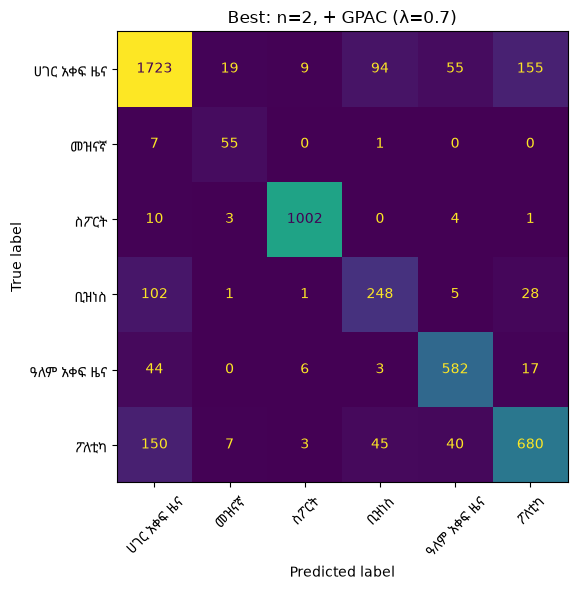

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
top = res.loc[res.accuracy.idxmax()]
pred = best[(top.n, top.model.split(" (")[0])]
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(te.category, pred, ax=ax, xticks_rotation=45, colorbar=False)
from matplotlib import font_manager
from ngram.viz import ethiopic_font
font_manager.fontManager.addfont(ethiopic_font(DATA))
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_fontfamily(font_manager.FontProperties(fname=ethiopic_font(DATA)).get_name())
ax.set_title(f"Best: n={top.n}, {top.model}"); plt.tight_layout()
plt.savefig(f"{FIGURES}/confusion_matrix.png", dpi=150)
from sklearn.metrics import classification_report
print(classification_report(te.category, pred, digits=3))

## 3.2 Next-word prediction and keystroke savings

Each test sentence is "typed" word by word. Before each of the first three characters of a word,
the top-5 suggestions given the previous words (and the characters typed so far) are shown. If the
word is among them, it is selected with one keystroke. Otherwise the user types it in full.

- **top-1 / top-5 accuracy:** the next word is the first / among the five suggestions before any
  character of it is typed.
- **keystroke savings:** 1 − (keystrokes with suggestions) / (keystrokes without), where a character
  is one Ethiopic syllable (fidel) and each word costs one extra keystroke for the space.

In [6]:
from ngram.corpus import read_sentences
from ngram.evaluate import keystroke_savings
from ngram.generate import Suggester
N_SENT = 300
test_sents = list(read_sentences(f"{MODEL_DIR}/test.txt", limit=N_SENT))
ks = [{"n": n, **keystroke_savings(Suggester(KneserNeyModel(counts, n), vocab), test_sents)}
      for n in range(1, 5)]
pd.DataFrame(ks).round(4)

,n,top1_accuracy,top5_accuracy,keystroke_savings,words
0,1,0.0186,0.0466,0.2981,3930
1,2,0.1018,0.2204,0.4937,3930
2,3,0.2097,0.3369,0.5336,3930
3,4,0.2430,0.3550,0.5381,3930


### Discussion

**Classification.**

- Every n-gram classifier is far above the majority-class baseline: 40.3 % accuracy and 0.096
  macro-F1.
- The unigram class models are a multinomial naive Bayes classifier (77.3 %, macro-F1 0.737).
  Bigrams add phrase evidence such as names, titles and fixed expressions, and raise accuracy to
  82.8 % (0.776). Trigrams and 4-grams add almost nothing on their own (82.8 %, 83.1 %). Each class
  has only 0.5–6 M training tokens, so most of their 3- and 4-grams are seen once or never.
- Interpolating with the GPAC model helps every order above 1. The best system is the bigram model
  with λ = 0.7: 84.1 % accuracy and macro-F1 0.805, against 0.776 without GPAC. GPAC supplies
  reliable probabilities for word sequences the small class corpora never saw, so the class
  models can concentrate on what distinguishes the categories. For n = 3 and 4 the dev set
  selects λ = 0.3, giving GPAC most of the weight.
- Per class, sport is nearly perfect (F1 0.98) because its vocabulary (teams, scores,
  competitions) is distinctive. Business (0.64) and politics (0.75) are confused with national
  news, which covers the same government and economic topics.
- **Caveat:** GPAC and this dataset both draw on Ethiopian news sites. If GPAC contains some of the
  test articles, the "+ GPAC" rows are slightly optimistic.

**Keystroke savings.**

- Going from n = 1 to n = 2 raises top-5 next-word accuracy from 4.7 % to 22.0 % and keystroke
  savings from 29.8 % to 49.4 %. The suggestions change from "frequent words" to "words that fit
  after the previous word".
- n = 3 and 4 add less: 33.7 % and 35.5 % top-5, and 53.4 % and 53.8 % savings. Long histories
  are often unseen or pruned, and then the model backs off to the bigram.
- The unigram model's 30 % savings comes almost entirely from completing a word once its first
  characters are typed.

**Intrinsic vs. extrinsic.** Perplexity improves steadily up to n = 4 (Task 2), but both
downstream tasks saturate at n = 2–3. Lower perplexity does not guarantee a better application.
Classification needs only the *relative* likelihood of a text under different classes, and
next-word suggestion needs only the top few candidates.